# TCGA-KIRC: model performance and robustness

This notebook evaluates the internal model performance and robustness of results of the myeloid-inflammation survival association identified in myprevious stage 05 output .

I will compare a clinical baseline model with a clinical-plus-myeloid model, assess proportional-hazards assumptions, estimate using bootstrap internal validation, and perform a (sensitivity analysis) excluding patients(only 4 patients exactly) with multiple available expression files.

## 06-01 Importing packages

In [19]:
from pathlib import Path

import numpy as np
import pandas as pd

from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

## 06-02 preparing model variables

In [21]:
PROJECT_DIR = Path.cwd().parent
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

clinical_signature_file = (
    PROCESSED_DATA_DIR
    / "tcga_kirc_clinical_immune_signature_analysis_data.csv"
)

selection_file = (
    PROJECT_DIR / "docs" / "tcga_kirc_expression_file_selection.csv"
)

analysis_data = pd.read_csv(clinical_signature_file)
expression_selection = pd.read_csv(selection_file)

analysis_data["age_per_10_years"] = (
    analysis_data["age_at_index"] / 10
)

analysis_data["male"] = (
    analysis_data["sex_at_birth"] == "male"
).astype(int)

analysis_data["high_grade"] = (
    analysis_data["tumor_grade"].isin(["G3", "G4"])
).astype(int)

analysis_data["myeloid_score_per_sd"] = (
    analysis_data["myeloid_inflammation_score"]
    - analysis_data["myeloid_inflammation_score"].mean()
) / analysis_data["myeloid_inflammation_score"].std()

clinical_covariates = [
    "age_per_10_years",
    "male",
    "high_grade",
]

multi_file_patient_ids = expression_selection.loc[
    expression_selection["selection_reason"] == "preferred_01A_then_aliquot",
    "patient_id",
].tolist()

print("Patients:", len(analysis_data))
print("Deaths:", analysis_data["event_observed"].sum())
print("Patients with multiple candidate expression files:", len(multi_file_patient_ids))
print("Patient IDs:", multi_file_patient_ids)

Patients: 518
Deaths: 171
Patients with multiple candidate expression files: 4
Patient IDs: ['TCGA-B2-3923', 'TCGA-B2-3924', 'TCGA-B2-5633', 'TCGA-B2-5635']


## 06-03 Fitting clinical-only and clinical-plus-myeloid models

In [22]:


baseline_model_columns = [
    "overall_survival_days",
    "event_observed",
    "tumor_stage",
] + clinical_covariates

myeloid_model_columns = baseline_model_columns + [
    "myeloid_score_per_sd"
]

baseline_model_data = analysis_data[baseline_model_columns].copy()
myeloid_model_data = analysis_data[myeloid_model_columns].copy()

clinical_model = CoxPHFitter()
clinical_model.fit(
    baseline_model_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
    strata=["tumor_stage"],
)

clinical_myeloid_model = CoxPHFitter()
clinical_myeloid_model.fit(
    myeloid_model_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
    strata=["tumor_stage"],
)

print(
    "Clinical-model concordance index: "
    f"{clinical_model.concordance_index_:.3f}"
)

print(
    "Clinical-plus-myeloid concordance index: "
    f"{clinical_myeloid_model.concordance_index_:.3f}"
)

Clinical-model concordance index: 0.629
Clinical-plus-myeloid concordance index: 0.649


## 06-04 Summarize the added myeloid-inflammation association

In [36]:

myeloid_result = clinical_myeloid_model.summary.loc[
    "myeloid_score_per_sd",
    [
        "exp(coef)",
        "exp(coef) lower 95%",
        "exp(coef) upper 95%",
        "p",
    ],
].to_frame().T

myeloid_result.columns = [
    "hazard_ratio_per_SD",
    "lower_95_CI",
    "upper_95_CI",
    "p_value",
]

myeloid_result["clinical_model_c_index"] = (
    clinical_model.concordance_index_
)

myeloid_result["clinical_plus_myeloid_c_index"] = (
    clinical_myeloid_model.concordance_index_
)

myeloid_result["apparent_c_index_change"] = (
    clinical_myeloid_model.concordance_index_
    - clinical_model.concordance_index_
)

display(myeloid_result.round(3))

,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value,clinical_model_c_index,clinical_plus_myeloid_c_index,apparent_c_index_change
myeloid_score_per_sd,1.35,1.175,1.551,0.0,0.629,0.649,0.019


myeloid score improves apparent discrimination by 0.019 (0.629 → 0.649). Now letme check whether its estimated effect is stable over follow-up time

## 06-05 Checking proportional-hazards assumptions

In [24]:

ph_check_results = []

for time_transform in ["rank", "km", "identity", "log"]:
    ph_test = proportional_hazard_test(
        clinical_myeloid_model,
        myeloid_model_data,
        time_transform=time_transform,
    )

    ph_summary = ph_test.summary.copy()
    ph_summary.index.name = "covariate"
    ph_summary = ph_summary.reset_index()
    ph_summary["time_transform"] = time_transform

    ph_check_results.append(ph_summary)

ph_check_results = pd.concat(
    ph_check_results,
    ignore_index=True,
)

ph_check_results = ph_check_results[
    ["time_transform", "covariate", "test_statistic", "p"]
].rename(columns={"p": "p_value"})

display(ph_check_results.round(4))

,time_transform,covariate,test_statistic,p_value
0,rank,age_per_10_years,4.2046,0.0403
1,rank,high_grade,2.4373,0.1185
2,rank,male,1.1602,0.2814
3,rank,myeloid_score_per_sd,0.0025,0.9602
4,km,age_per_10_years,0.0374,0.8466
5,km,high_grade,0.3234,0.5696
6,km,male,0.0158,0.9000
7,km,myeloid_score_per_sd,0.5607,0.4540
8,identity,age_per_10_years,0.2934,0.5880
9,identity,high_grade,0.3123,0.5763


## 06-06 Sensitivity analysis excluding 4 multiple expression files patients

In [26]:

sensitivity_data = analysis_data[
    ~analysis_data["patient_id"].isin(multi_file_patient_ids)
].copy()

sensitivity_model_data = sensitivity_data[myeloid_model_columns].copy()

sensitivity_model = CoxPHFitter()

sensitivity_model.fit(
    sensitivity_model_data,
    duration_col="overall_survival_days",
    event_col="event_observed",
    strata=["tumor_stage"],
)

sensitivity_summary = sensitivity_model.summary.loc[
    "myeloid_score_per_sd",
    [
        "exp(coef)",
        "exp(coef) lower 95%",
        "exp(coef) upper 95%",
        "p",
    ],
]

sensitivity_comparison = pd.DataFrame(
    {
        "analysis": [
            "Primary analysis: all matched patients",
            "Sensitivity: exclude multi-file patients",
        ],
        "patients": [
            len(analysis_data),
            len(sensitivity_data),
        ],
        "deaths": [
            analysis_data["event_observed"].sum(),
            sensitivity_data["event_observed"].sum(),
        ],
        "hazard_ratio_per_SD": [
            myeloid_result.loc[
                "myeloid_score_per_sd",
                "hazard_ratio_per_SD",
            ],
            sensitivity_summary["exp(coef)"],
        ],
        "lower_95_CI": [
            myeloid_result.loc[
                "myeloid_score_per_sd",
                "lower_95_CI",
            ],
            sensitivity_summary["exp(coef) lower 95%"],
        ],
        "upper_95_CI": [
            myeloid_result.loc[
                "myeloid_score_per_sd",
                "upper_95_CI",
            ],
            sensitivity_summary["exp(coef) upper 95%"],
        ],
        "p_value": [
            myeloid_result.loc[
                "myeloid_score_per_sd",
                "p_value",
            ],
            sensitivity_summary["p"],
        ],
    }
)

display(sensitivity_comparison.round(3))

,analysis,patients,deaths,hazard_ratio_per_SD,lower_95_CI,upper_95_CI,p_value
0,Primary analysis: all matched patients,518,171,1.350,1.175,1.551,0.0
1,Sensitivity: exclude multi-file patients,514,171,1.349,1.174,1.550,0.0


Excluding all four multi-file patients changes the HR only from 1.350 to 1.349.

The myeloid score passes every proportional-hazards check (p ≥ 0.44)

Age has a rank-test signal (p = 0.040), but as we have noticed in stage2 
its not consistent across transformations

## 06-07 Bootstrap internal validation of model discrimination: It trains on each bootstrap sample and evaluates only patients not selected in that sample

In [35]:
from lifelines.utils import concordance_index

random_generator = np.random.default_rng(20261020)

bootstrap_results = []

for bootstrap_number in range(1, 201):
    bootstrap_indices = []

    for stage in analysis_data["tumor_stage"].unique():
        stage_indices = np.flatnonzero(
            analysis_data["tumor_stage"].to_numpy() == stage
        )

        sampled_indices = random_generator.choice(
            stage_indices,
            size=len(stage_indices),
            replace=True,
        )

        bootstrap_indices.extend(sampled_indices)

    bootstrap_indices = np.array(bootstrap_indices)

    out_of_bag_indices = np.setdiff1d(
        np.arange(len(analysis_data)),
        np.unique(bootstrap_indices),
    )

    out_of_bag_baseline_data = baseline_model_data.iloc[
        out_of_bag_indices
    ].copy()

    out_of_bag_myeloid_data = myeloid_model_data.iloc[
        out_of_bag_indices
    ].copy()

    if out_of_bag_baseline_data["event_observed"].nunique() < 2:
        continue

    bootstrap_baseline_data = baseline_model_data.iloc[
        bootstrap_indices
    ].copy()

    bootstrap_myeloid_data = myeloid_model_data.iloc[
        bootstrap_indices
    ].copy()

    bootstrap_clinical_model = CoxPHFitter()
    bootstrap_clinical_model.fit(
        bootstrap_baseline_data,
        duration_col="overall_survival_days",
        event_col="event_observed",
        strata=["tumor_stage"],
    )

    bootstrap_myeloid_model = CoxPHFitter()
    bootstrap_myeloid_model.fit(
        bootstrap_myeloid_data,
        duration_col="overall_survival_days",
        event_col="event_observed",
        strata=["tumor_stage"],
    )

    clinical_out_of_bag_risk = (
        bootstrap_clinical_model.predict_partial_hazard(
            out_of_bag_baseline_data
        )
    )

    myeloid_out_of_bag_risk = (
        bootstrap_myeloid_model.predict_partial_hazard(
            out_of_bag_myeloid_data
        )
    )

    clinical_out_of_bag_c_index = concordance_index(
        out_of_bag_baseline_data["overall_survival_days"],
        -clinical_out_of_bag_risk,
        out_of_bag_baseline_data["event_observed"],
    )

    myeloid_out_of_bag_c_index = concordance_index(
        out_of_bag_myeloid_data["overall_survival_days"],
        -myeloid_out_of_bag_risk,
        out_of_bag_myeloid_data["event_observed"],
    )

    bootstrap_results.append(
        {
            "bootstrap_number": bootstrap_number,
            "clinical_out_of_bag_c_index": clinical_out_of_bag_c_index,
            "myeloid_out_of_bag_c_index": myeloid_out_of_bag_c_index,
            "out_of_bag_c_index_change": (
                myeloid_out_of_bag_c_index
                - clinical_out_of_bag_c_index
            ),
        }
    )

    if bootstrap_number % 20 == 0:
        print(f"Yayy, ...completed {bootstrap_number} of total bootstrap samples")

bootstrap_results = pd.DataFrame(bootstrap_results)

bootstrap_summary = pd.DataFrame(
    {
        "model": ["Clinical only", "Clinical plus myeloid score"],
        "apparent_full_cohort_c_index": [
            clinical_model.concordance_index_,
            clinical_myeloid_model.concordance_index_,
        ],
        "mean_out_of_bag_c_index": [
            bootstrap_results["clinical_out_of_bag_c_index"].mean(),
            bootstrap_results["myeloid_out_of_bag_c_index"].mean(),
        ],
        "lower_95_percentile": [
            bootstrap_results["clinical_out_of_bag_c_index"].quantile(0.025),
            bootstrap_results["myeloid_out_of_bag_c_index"].quantile(0.025),
        ],
        "upper_95_percentile": [
            bootstrap_results["clinical_out_of_bag_c_index"].quantile(0.975),
            bootstrap_results["myeloid_out_of_bag_c_index"].quantile(0.975),
        ],
    }
)

print("Successful bootstrap samples:", len(bootstrap_results))

display(bootstrap_summary.round(3))

print(
    "Mean out-of-bag C-index change: "
    f"{bootstrap_results['out_of_bag_c_index_change'].mean():.3f}"
)

Yayy, ...completed 20 of total bootstrap samples
Yayy, ...completed 40 of total bootstrap samples
Yayy, ...completed 60 of total bootstrap samples
Yayy, ...completed 80 of total bootstrap samples
Yayy, ...completed 100 of total bootstrap samples
Yayy, ...completed 120 of total bootstrap samples
Yayy, ...completed 140 of total bootstrap samples
Yayy, ...completed 160 of total bootstrap samples
Yayy, ...completed 180 of total bootstrap samples
Yayy, ...completed 200 of total bootstrap samples
Successful bootstrap samples: 200


,model,apparent_full_cohort_c_index,mean_out_of_bag_c_index,lower_95_percentile,upper_95_percentile
0,Clinical only,0.629,0.641,0.575,0.699
1,Clinical plus myeloid score,0.649,0.664,0.597,0.721


Mean out-of-bag C-index change: 0.023


The clinical-plus-myeloid model has a higher mean out-of-bag C-index (0.664) than the clinical-only model (0.641), with a mean improvement of 0.023. This supports a modest but consistent improvement in discrimination within TCGA

## 06-08 bootstrap model improvment

In [32]:
bootstrap_change_summary = pd.DataFrame(
    {
        "mean_out_of_bag_c_index_change": [
            bootstrap_results["out_of_bag_c_index_change"].mean()
        ],
        "lower_95_percentile": [
            bootstrap_results["out_of_bag_c_index_change"].quantile(0.025)
        ],
        "upper_95_percentile": [
            bootstrap_results["out_of_bag_c_index_change"].quantile(0.975)
        ],
        "proportion_with_improvement": [
            (
                bootstrap_results["out_of_bag_c_index_change"] > 0
            ).mean()
        ],
    }
)

display(bootstrap_change_summary.round(3))

,mean_out_of_bag_c_index_change,lower_95_percentile,upper_95_percentile,proportion_with_improvement
0,0.023,-0.015,0.052,0.905


## 06-09  Plotting some figures to see 


/var/folders/dy/g7qs6yvj71d5kt43gwgy2k3c0000gn/T/ipykernel_16020/387599941.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


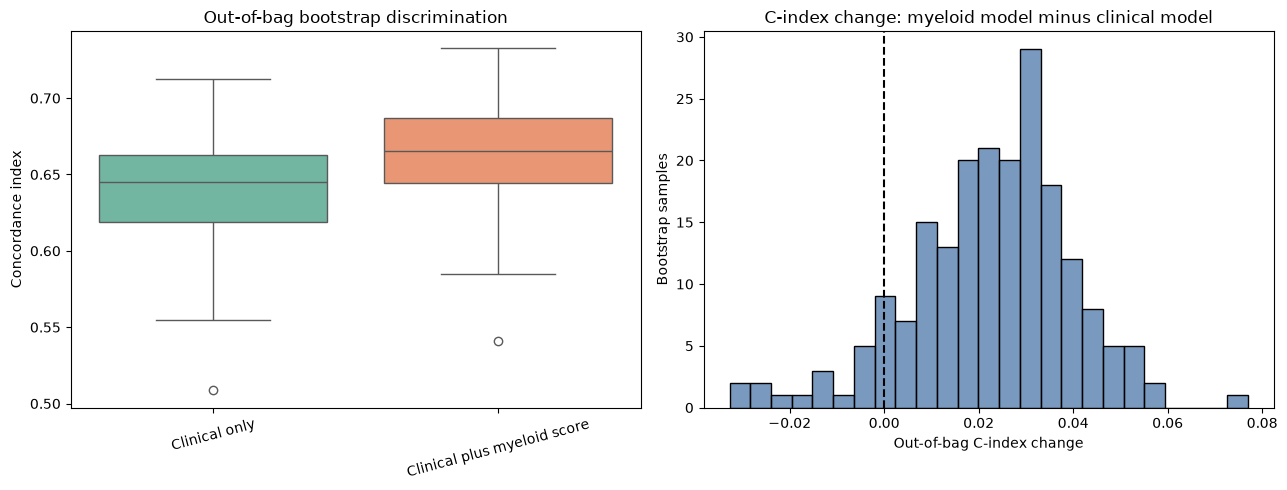

Figure saved as: figure_09_bootstrap_model_performance.png


In [33]:

import matplotlib.pyplot as plt
import seaborn as sns

bootstrap_plot_data = bootstrap_results.melt(
    id_vars="bootstrap_number",
    value_vars=[
        "clinical_out_of_bag_c_index",
        "myeloid_out_of_bag_c_index",
    ],
    var_name="model",
    value_name="out_of_bag_c_index",
)

bootstrap_plot_data["model"] = bootstrap_plot_data["model"].replace(
    {
        "clinical_out_of_bag_c_index": "Clinical only",
        "myeloid_out_of_bag_c_index": "Clinical plus myeloid score",
    }
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=bootstrap_plot_data,
    x="model",
    y="out_of_bag_c_index",
    palette="Set2",
    ax=axes[0],
)

axes[0].set_title("Out-of-bag bootstrap discrimination")
axes[0].set_xlabel("")
axes[0].set_ylabel("Concordance index")
axes[0].tick_params(axis="x", rotation=15)

sns.histplot(
    data=bootstrap_results,
    x="out_of_bag_c_index_change",
    bins=25,
    color="#4C78A8",
    ax=axes[1],
)

axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("C-index change: myeloid model minus clinical model")
axes[1].set_xlabel("Out-of-bag C-index change")
axes[1].set_ylabel("Bootstrap samples")

plt.tight_layout()

figure_file = (
    RESULTS_DIR / "figures" / "figure_09_bootstrap_model_performance.png"
)

fig.savefig(figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {figure_file.name}")

## 06-10  its time to save rsults

In [34]:
RESULTS_TABLE_DIR = RESULTS_DIR / "tables"
RESULTS_TABLE_DIR.mkdir(parents=True, exist_ok=True)

ph_results_file = (
    RESULTS_TABLE_DIR / "table_05_myeloid_model_proportional_hazards_checks.csv"
)

sensitivity_results_file = (
    RESULTS_TABLE_DIR / "table_06_multi_file_patient_sensitivity_analysis.csv"
)

bootstrap_results_file = (
    RESULTS_TABLE_DIR / "table_07_out_of_bag_bootstrap_performance.csv"
)

bootstrap_summary_file = (
    RESULTS_TABLE_DIR / "table_08_bootstrap_performance_summary.csv"
)

ph_check_results.to_csv(ph_results_file, index=False)
sensitivity_comparison.to_csv(sensitivity_results_file, index=False)
bootstrap_results.to_csv(bootstrap_results_file, index=False)
bootstrap_summary.to_csv(bootstrap_summary_file, index=False)

print(f"Saved: {ph_results_file.name}")
print(f"Saved: {sensitivity_results_file.name}")
print(f"Saved: {bootstrap_results_file.name}")
print(f"Saved: {bootstrap_summary_file.name}")

Saved: table_05_myeloid_model_proportional_hazards_checks.csv
Saved: table_06_multi_file_patient_sensitivity_analysis.csv
Saved: table_07_out_of_bag_bootstrap_performance.csv
Saved: table_08_bootstrap_performance_summary.csv


# summary

The adjusted myeloid-inflammation association was unchanged after excluding the four patients with multiple available expression files. The myeloid score also showed no evidence of proportional-hazards violation across four time transformations.

In 200 stratified out-of-bag bootstrap samples, adding the myeloid-inflammation score improved mean discrimination beyond the clinical-only model. This is internal validation success; I am goijng to move forward to check this biomarker against independent external validation dataset for reproducibility.